# Pandas AI Functions Starter Notebook

Learn to use pandas AI Functions by building a transformation workflow on a customer-review dataset.

## What You'll Do
1. Set shared default configurations.
2. Load a public review sample and inspect rating and review-length patterns before enrichment.
3. Walk through all nine Fabric AI Functions for data enrichment in one customer-feedback workflow.
4. Build a compact dashboard and review common pandas configuration options.

## Before You Start
- **Runtime**: Fabric Runtime 1.3 or later.
- **Temporary dependency**: Pandas AI Functions currently require the `openai` Python package in the notebook session.
- **Cost control**: Start with a small number of `SAMPLE_ROWS`, then scale up after you are happy with output quality.

| Resource | Link |
|---|---|
| AI Functions overview | [aka.ms/ai-functions](https://aka.ms/ai-functions) |
| Pandas configuration docs | [Pandas AI Function Config Doc](https://learn.microsoft.com/en-us/fabric/data-science/ai-functions/pandas/configuration) |
| Model catalog | [aka.ms/fabric-ai-models](https://aka.ms/fabric-ai-models) |
| More starter notebook examples | [aka.ms/fabric-aifunctions-starter-notebooks](https://aka.ms/fabric-aifunctions-starter-notebooks) |
| More eval notebook examples | [aka.ms/fabric-aifunctions-eval-notebooks](https://aka.ms/fabric-aifunctions-eval-notebooks) |


## 1. Imports and Installs
Pandas AI Functions currently require the `openai` Python package to be installed in the notebook session.

In [ ]:
%pip install datasets

StatementMeta(, e18f93f0-e0fd-40e4-a544-51ce147078bd, 45, Finished, Available, Finished, True)


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: /nfs4/pyenv-28ac5c86-ae23-44a1-ba7e-4421b5b48d99/bin/python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [ ]:
%pip install nest_asyncio

StatementMeta(, e18f93f0-e0fd-40e4-a544-51ce147078bd, 51, Finished, Available, Finished, True)


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: /nfs4/pyenv-28ac5c86-ae23-44a1-ba7e-4421b5b48d99/bin/python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [ ]:
%pip install -q openai 2>/dev/null

StatementMeta(, e18f93f0-e0fd-40e4-a544-51ce147078bd, 57, Finished, Available, Finished, True)

Note: you may need to restart the kernel to use updated packages.


In [ ]:
import json
from textwrap import dedent
from typing import Literal

import matplotlib.pyplot as plt
import pandas as pd
import synapse.ml.aifunc as aifunc
from pydantic import BaseModel, Field

# Number of reviews to sample — keep small for fast iteration
SAMPLE_ROWS = 20

StatementMeta(, e18f93f0-e0fd-40e4-a544-51ce147078bd, 59, Finished, Available, Finished, False)

/home/trusted-service-user/cluster-env/trident_env/lib/python3.13/site-packages/synapse/ml/core/_proto_compat.py:38: UserWarning: google.protobuf.service module is deprecated. RPC implementations should provide code generator plugins which generate code specific to the RPC implementation. service.py will be removed in Jan 2025
  import google.protobuf.service  # type: ignore  # noqa: F401


In [ ]:
# Shared chart styling and color palette
plt.style.use("seaborn-v0_8-whitegrid")

FABRIC_BLUE = "#4C78A8"
FABRIC_TEAL = "#72B7B2"
FABRIC_ORANGE = "#F58518"
FABRIC_RED = "#E45756"
FABRIC_GRAY = "#9D9DA1"
SENTIMENT_COLORS = {
    "positive": "#54A24B",
    "negative": FABRIC_RED,
    "neutral": FABRIC_GRAY,
    "mixed": FABRIC_ORANGE,
}
PRIORITY_COLORS = {
    "high": FABRIC_RED,
    "medium": FABRIC_ORANGE,
    "low": FABRIC_TEAL,
}

StatementMeta(, e18f93f0-e0fd-40e4-a544-51ce147078bd, 60, Finished, Available, Finished, False)

### 1.1 Shared defaults and targeted overrides

Pandas AI Functions support two configuration layers:
- `aifunc.default_conf` for shared session defaults
- `aifunc.Conf(...)` for targeted per-call overrides

Use `aifunc.default_conf` for workflow-wide settings. This walkthrough uses `gpt-5-mini` with low reasoning effort. Use `ai.<ai_function_name>(..., conf=aifunc.Conf(...))` only when a specific step needs a focused override, such as the evaluation pass later in the notebook.

In [ ]:
# Global defaults for the walkthrough.
# see https://aka.ms/fabric-ai-models for other models
aifunc.default_conf.model_deployment_name = "gpt-5-mini"  # LLM powering the AI Functions.
aifunc.default_conf.embedding_deployment_name = "text-embedding-ada-002"  # Embedding model powering ai.embed and ai.similarity
aifunc.default_conf.reasoning_effort = "low"  # Balance quality, latency, and token usage.
aifunc.default_conf.progress_bar_mode = "stats"  # Show token counts and CU estimates in the progress bar.


StatementMeta(, e18f93f0-e0fd-40e4-a544-51ce147078bd, 61, Finished, Available, Finished, False)

### 1.2 Common pandas configuration options

| `default_conf` attribute | Why you would use it |
|---|---|
| `api_type` | Select the model API surface. `"responses"` is the default; use `"chat_completions"` only for compatible custom models. |
| `model_deployment_name` | Choose the text model deployment. |
| `embedding_deployment_name` | Choose the embedding model deployment. |
| `reasoning_effort` | Tune reasoning depth for GPT-5 series models. |
| `verbosity` | Control response detail for GPT-5 series models when a task benefits from shorter or more detailed output. |
| `temperature` | Adjust randomness for non-reasoning models; leave unset for GPT-5 series reasoning models. |
| `top_p` | Adjust nucleus sampling for non-reasoning models; leave unset for GPT-5 series reasoning models. |
| `seed` | Improve reproducibility when using the Chat Completions API; omit it for the default Responses API. |
| `timeout` | Set the number of seconds before an AI Function raises a timeout error. |
| `concurrency` | Set the maximum number of rows processed asynchronously. |
| `progress_bar_mode` | Show token and CU stats during execution (`"stats"`). |

Use `aifunc.Conf(...)` for per-call overrides when a specific step needs a focused configuration change, such as a different model, reasoning effort, or verbosity. For complete parameter details, see [Pandas AI Function Config Doc](https://learn.microsoft.com/en-us/fabric/data-science/ai-functions/pandas/configuration).


## 2. Load data and profile the sample

We use a small public sample from Amazon Reviews 2023 (Sports and Outdoors) to keep iteration fast. The quick profile below helps you understand the rating mix and review length before AI enrichment.

In [ ]:
# Load a small in-notebook Amazon-style reviews sample instead of calling Hugging Face Hub
# This avoids external network and package dependencies while preserving the same
# columns used throughout the rest of the notebook.

sample_rows = [
    {
        "review_title": "Great value for the price",
        "review_text": "These headphones work surprisingly well for the price. Sound is clear and the battery lasts all day.",
        "rating": 5,
    },
    {
        "review_title": "Poor build quality",
        "review_text": "The handle broke after two weeks of light use. Very disappointed in the build quality.",
        "rating": 2,
    },
    {
        "review_title": "Shipping was delayed",
        "review_text": "The product itself is fine, but shipping took almost three weeks and the box arrived damaged.",
        "rating": 3,
    },
    {
        "review_title": "Exactly as described",
        "review_text": "Item matches the description and works as expected. No complaints so far.",
        "rating": 4,
    },
    {
        "review_title": "Not worth it",
        "review_text": "Stopped working after a month. Customer service was unhelpful and refused a refund.",
        "rating": 1,
    },
]

# Optionally cap by SAMPLE_ROWS defined earlier
max_rows = SAMPLE_ROWS if "SAMPLE_ROWS" in globals() else len(sample_rows)

df = pd.DataFrame(sample_rows[:max_rows]).copy().reset_index(drop=True)

# Ensure column names and types align with downstream cells
df["review_title"] = df["review_title"].fillna("").astype(str)
df["review_text"] = df["review_text"].fillna("").astype(str)

load_info = pd.DataFrame(
    {
        "metric": ["rows_loaded", "columns", "dataset_config"],
        "value": [len(df), ", ".join(df.columns), "local_sample_reviews"],
    }
)

display(load_info)
display(df.head(10))

StatementMeta(, e18f93f0-e0fd-40e4-a544-51ce147078bd, 62, Finished, Available, Finished, False)

SynapseWidget(Synapse.DataFrame, 431a2385-a31c-4233-974d-f65a0e401db7)

SynapseWidget(Synapse.DataFrame, 129ea3a1-9561-4193-bc3c-27428a651930)

StatementMeta(, e18f93f0-e0fd-40e4-a544-51ce147078bd, 63, Finished, Available, Finished, False)

SynapseWidget(Synapse.DataFrame, 4ce5214f-5aca-4a8e-b84d-b755efbbf0da)

SynapseWidget(Synapse.DataFrame, 775cbdd2-4a30-4fa3-adac-b22697d6c485)

SynapseWidget(Synapse.DataFrame, 2b05d9de-89ad-4ddd-add0-70e1fdf8c026)

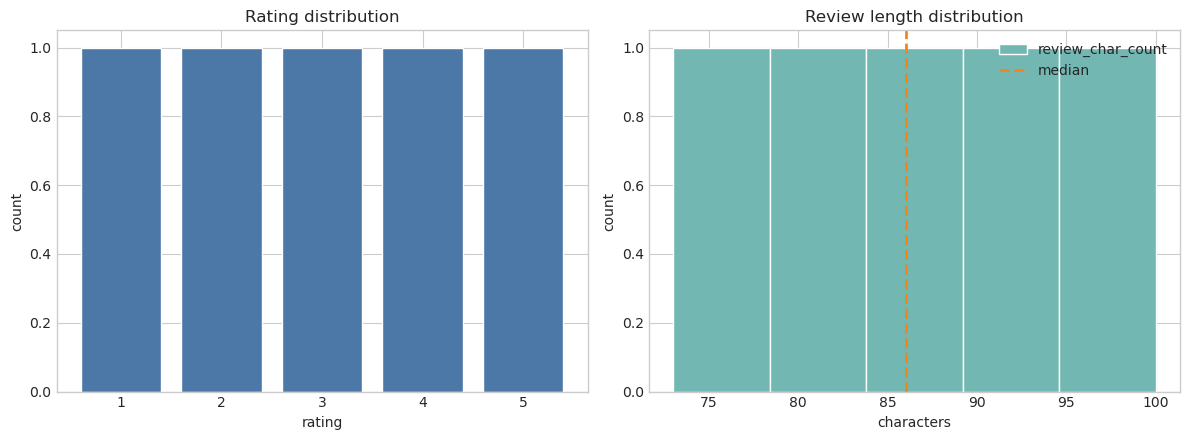

In [ ]:
# Measure review length for the distribution chart below
df["review_char_count"] = df["review_text"].astype(str).str.len()

# Count reviews per rating
rating_counts = (
    df["rating"]
    .fillna("missing")
    .astype(str)
    .value_counts()
    .rename_axis("rating")
    .reset_index(name="count")
    .sort_values("rating")
)

# Quick summary statistics
eda_summary = pd.DataFrame(
    {
        "metric": [
            "row_count",
            "avg_review_char_count",
            "median_review_char_count",
            "missing_ratings",
        ],
        "value": [
            len(df),
            round(df["review_char_count"].mean(), 1),
            round(df["review_char_count"].median(), 1),
            int(df["rating"].isna().sum()),
        ],
    }
)

display(eda_summary)
display(rating_counts)
display(
    df[["rating", "review_char_count"]]
    .describe(include="all")
    .transpose()
    .reset_index()
    .rename(columns={"index": "column"})
)

# Side-by-side charts: rating breakdown and review-length histogram
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].bar(rating_counts["rating"], rating_counts["count"], color=FABRIC_BLUE, edgecolor="white")
axes[0].set_title("Rating distribution")
axes[0].set_xlabel("rating")
axes[0].set_ylabel("count")

df["review_char_count"].plot.hist(
    ax=axes[1],
    bins=min(12, max(5, len(df) // 2)),
    color=FABRIC_TEAL,
    edgecolor="white",
)
axes[1].axvline(
    df["review_char_count"].median(),
    color=FABRIC_ORANGE,
    linestyle="--",
    linewidth=2,
    label="median",
)
axes[1].set_title("Review length distribution")
axes[1].set_xlabel("characters")
axes[1].set_ylabel("count")
axes[1].legend()

plt.tight_layout()
plt.show()

## 3. Walk through the AI Functions

This example workflow moves from signal detection -> enrichment -> action: start with sentiment and topic labels, extract structured facts, condense and clean the text, add semantic signals, and finish with support-ready outputs.

### 3.1 `ai.analyze_sentiment`

Start with sentiment so every downstream step has a first-pass triage signal.

In [ ]:
# Apply a small asyncio compatibility patch so pandas AI Functions can run inside the
# Fabric notebook event loop without raising "This event loop is already running".
try:
    import nest_asyncio  # type: ignore

    nest_asyncio.apply()
except ModuleNotFoundError as e:
    raise ModuleNotFoundError(
        "The 'nest_asyncio' package is required to run pandas AI Functions in this "
        "notebook environment. Add and run a new cell ABOVE this one with:\n\n"
        "    %pip install nest_asyncio\n\n"
        "Then re-run the notebook from the top."
    ) from e

# Now run the sentiment analysis step
df["sentiment"] = df["review_text"].ai.analyze_sentiment()

display(df[["review_text", "rating", "sentiment"]].head(10))

StatementMeta(, e18f93f0-e0fd-40e4-a544-51ce147078bd, 64, Finished, Available, Finished, False)

/home/trusted-service-user/cluster-env/trident_env/lib/python3.13/site-packages/synapse/ml/aifunc/_client.py:272: UserWarning: conf.temperature is not supported for model gpt-5-mini; overriding to NOT_GIVEN
  warnings.warn(f"conf.temperature is not supported for model {model}; overriding to NOT_GIVEN")
ai.analyze_sentiment:   0%|          | 0/5 [00:00<?, ?it/s]

ai.analyze_sentiment:  60%|██████    | 3/5 [00:01<00:03,  1.71s/it, cached=0->0.00, in=280->350.00, out=250->312.50, CU-s=17.04->21.30]

ai.analyze_sentiment: 100%|██████████| 5/5 [00:01<00:00,  2.55it/s, cached=0, in=350, out=326, CU-s=22.21]


SynapseWidget(Synapse.DataFrame, 468a078a-8905-48c8-b28e-bc4bea0f8e05)

StatementMeta(, e18f93f0-e0fd-40e4-a544-51ce147078bd, 65, Finished, Available, Finished, False)

SynapseWidget(Synapse.DataFrame, 3968840d-b2f2-4bae-9f01-6afa786d1d12)

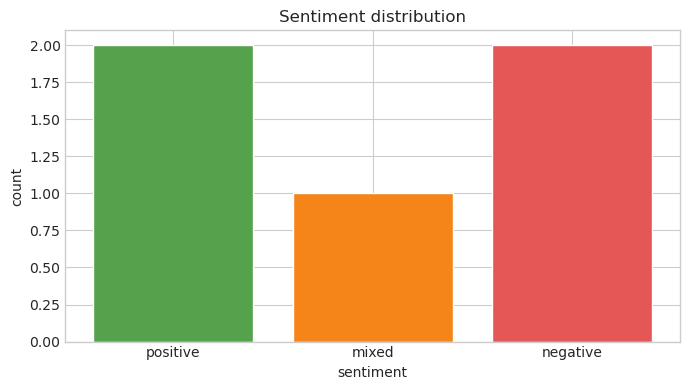

In [ ]:
# Define the display order for sentiment categories
sentiment_order = ["positive", "neutral", "mixed", "negative"]

# Count occurrences of each sentiment label
sentiment_counts = (
    df["sentiment"].astype(str).value_counts().rename_axis("sentiment").reset_index(name="count")
)

# Convert to an ordered categorical so the chart follows our preferred order
sentiment_counts["sentiment"] = pd.Categorical(
    sentiment_counts["sentiment"],
    categories=sentiment_order,
    ordered=True,
)
sentiment_counts = sentiment_counts.sort_values("sentiment").reset_index(drop=True)
display(sentiment_counts)

# Bar chart colored by sentiment category
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(
    sentiment_counts["sentiment"].astype(str),
    sentiment_counts["count"],
    color=[
        SENTIMENT_COLORS.get(value, FABRIC_BLUE)
        for value in sentiment_counts["sentiment"].astype(str)
    ],
    edgecolor="white",
)
ax.set_title("Sentiment distribution")
ax.set_xlabel("sentiment")
ax.set_ylabel("count")
plt.tight_layout()
plt.show()

### 3.2 `ai.classify`

Add a business topic so each review is easier to route to the right owner.

In [ ]:
# Define the candidate labels the model will choose from
TOPIC_LABELS = [
    "product_quality",
    "shipping_delivery",
    "customer_service",
    "price_value",
    "product_description",
]

# Classify each review into one of the above topics
df["topic"] = df["review_text"].ai.classify(*TOPIC_LABELS)

display(df[["review_text", "sentiment", "topic"]].head(10))

StatementMeta(, e18f93f0-e0fd-40e4-a544-51ce147078bd, 66, Finished, Available, Finished, False)

/home/trusted-service-user/cluster-env/trident_env/lib/python3.13/site-packages/synapse/ml/aifunc/_client.py:272: UserWarning: conf.temperature is not supported for model gpt-5-mini; overriding to NOT_GIVEN
  warnings.warn(f"conf.temperature is not supported for model {model}; overriding to NOT_GIVEN")
ai.classify:   0%|          | 0/5 [00:00<?, ?it/s]

ai.classify:  20%|██        | 1/5 [00:02<00:08,  2.20s/it, cached=0->0.00, in=77->385.00, out=48->240.00, CU-s=3.29->16.46]

ai.classify:  40%|████      | 2/5 [00:02<00:02,  1.01it/s, cached=0->0.00, in=234->390.00, out=169->281.67, CU-s=11.56->19.26]

ai.classify:  80%|████████  | 4/5 [00:04<00:01,  1.13s/it, cached=0->0.00, in=308->385.00, out=327->509.05, CU-s=22.24->34.55]

ai.classify: 100%|██████████| 5/5 [00:06<00:00,  1.35s/it, cached=0, in=385, out=562, CU-s=38.11]


SynapseWidget(Synapse.DataFrame, 0bb737ba-6a81-45f1-a333-f2f7e3eb1c63)

StatementMeta(, e18f93f0-e0fd-40e4-a544-51ce147078bd, 67, Finished, Available, Finished, False)

SynapseWidget(Synapse.DataFrame, 4083b2e5-84e9-4bb2-849c-143ba2d9c25c)

SynapseWidget(Synapse.DataFrame, 367803b9-4dad-4dda-99bf-d7fa6ae9bd04)

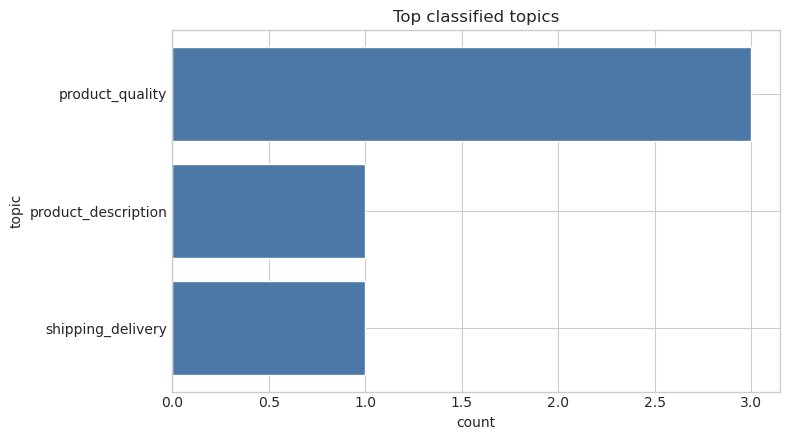

In [ ]:
# Count reviews per topic and build a topic × sentiment crosstab
topic_counts = df["topic"].astype(str).value_counts().rename_axis("topic").reset_index(name="count")
topic_counts = topic_counts.sort_values("count", ascending=True).reset_index(drop=True)

topic_sentiment = pd.crosstab(df["topic"].astype(str), df["sentiment"].astype(str)).reset_index()
display(topic_counts.sort_values("count", ascending=False).reset_index(drop=True))
display(topic_sentiment)

# Horizontal bar chart — sorted ascending so the most common topic appears at the top
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(topic_counts["topic"], topic_counts["count"], color=FABRIC_BLUE, edgecolor="white")
ax.set_title("Top classified topics")
ax.set_xlabel("count")
ax.set_ylabel("topic")
plt.tight_layout()
plt.show()

### 3.3 `ai.extract`

Extract product, brand, and issue details so the triage view contains concrete facts, not just labels.

In [ ]:
# Basic extraction with string labels
extracted = df["review_text"].ai.extract("product", "brand", "issue")
df = pd.concat([df, extracted], axis=1)

display(df[["review_text", "product", "brand", "issue"]].head(10))

StatementMeta(, e18f93f0-e0fd-40e4-a544-51ce147078bd, 68, Finished, Available, Finished, False)

/home/trusted-service-user/cluster-env/trident_env/lib/python3.13/site-packages/synapse/ml/aifunc/_client.py:272: UserWarning: conf.temperature is not supported for model gpt-5-mini; overriding to NOT_GIVEN
  warnings.warn(f"conf.temperature is not supported for model {model}; overriding to NOT_GIVEN")
ai.extract:   0%|          | 0/5 [00:00<?, ?it/s]

ai.extract:  40%|████      | 2/5 [00:08<00:10,  3.58s/it, cached=0->0.00, in=735->1.84k, out=449->1.12k, CU-s=30.80->77.01]

ai.extract:  60%|██████    | 3/5 [00:10<00:06,  3.01s/it, cached=0->0.00, in=1.46k->1.83k, out=1.10k->1.37k, CU-s=74.91->93.64]

ai.extract: 100%|██████████| 5/5 [00:11<00:00,  2.33s/it, cached=0, in=1.83k, out=1.46k, CU-s=99.56]


SynapseWidget(Synapse.DataFrame, 2601d69a-8213-4a97-b5ff-c1bde899c48c)

#### 3.3.1 Typed extraction with `aifunc.ExtractLabel`

Use `aifunc.ExtractLabel` when you want field descriptions and expected types in the extraction schema.

In [ ]:
# Define typed extraction labels with descriptions
typed_labels = [
    aifunc.ExtractLabel(
        label="price_mentioned",
        description="Any price or cost mentioned in the review",
        type="string",
    ),
    aifunc.ExtractLabel(
        label="is_repeat_customer",
        description="Whether the reviewer indicates they have purchased before",
        type="boolean",
    ),
]

typed_extracted = df["review_text"].ai.extract(*typed_labels)
df = pd.concat([df, typed_extracted], axis=1)

display(df[["review_text", "price_mentioned", "is_repeat_customer"]].head(10))

StatementMeta(, e18f93f0-e0fd-40e4-a544-51ce147078bd, 69, Finished, Available, Finished, False)

/home/trusted-service-user/cluster-env/trident_env/lib/python3.13/site-packages/synapse/ml/aifunc/_client.py:272: UserWarning: conf.temperature is not supported for model gpt-5-mini; overriding to NOT_GIVEN
  warnings.warn(f"conf.temperature is not supported for model {model}; overriding to NOT_GIVEN")
ai.extract:   0%|          | 0/5 [00:00<?, ?it/s]

ai.extract:  20%|██        | 1/5 [00:01<00:06,  1.56s/it, cached=0->0.00, in=324->1.62k, out=91->455.00, CU-s=6.39->31.95]

ai.extract: 100%|██████████| 5/5 [00:02<00:00,  2.31it/s, cached=0, in=1.62k, out=635, CU-s=44.05]


SynapseWidget(Synapse.DataFrame, 7bbdd16b-8387-44e4-ac73-63313a409a1f)

StatementMeta(, e18f93f0-e0fd-40e4-a544-51ce147078bd, 70, Finished, Available, Finished, False)

SynapseWidget(Synapse.DataFrame, 279a56b0-3c44-41ac-929c-c9c751db2d8d)

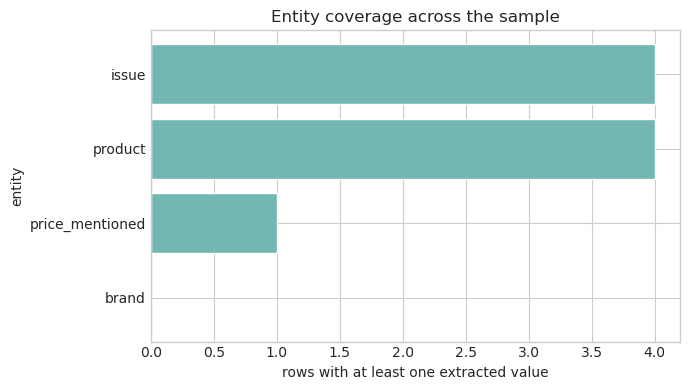

In [ ]:
def has_entity(value):
    """Return True when the extracted value is non-empty and meaningful."""
    if value is None:
        return False
    if isinstance(value, list):
        return len(value) > 0
    if isinstance(value, float) and pd.isna(value):
        return False
    return str(value).strip() != ""

# Count how many rows have a non-empty value for each extracted entity
entity_summary = pd.DataFrame(
    {
        "entity": ["product", "brand", "issue", "price_mentioned"],
        "rows_with_values": [
            int(df["product"].apply(has_entity).sum()),
            int(df["brand"].apply(has_entity).sum()),
            int(df["issue"].apply(has_entity).sum()),
            int(df["price_mentioned"].apply(has_entity).sum()),
        ],
    }
).sort_values("rows_with_values", ascending=True)
display(entity_summary)

# Visualize entity coverage to spot gaps in extraction
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(entity_summary["entity"], entity_summary["rows_with_values"], color=FABRIC_TEAL, edgecolor="white")
ax.set_title("Entity coverage across the sample")
ax.set_xlabel("rows with at least one extracted value")
ax.set_ylabel("entity")
plt.tight_layout()
plt.show()

#### 3.3.2 Evaluate and refine extracted issues with `ai.generate_response`

After extraction, add an evaluation column that reviews whether the extracted issue is ready for downstream triage and, when needed, produces a cleaner issue phrase. For richer judge-model patterns, multiple metrics, and side-by-side comparisons, see [aka.ms/fabric-aifunctions-eval-notebooks](https://aka.ms/fabric-aifunctions-eval-notebooks).

In [ ]:
EXTRACT_FIELDS = ["product", "brand", "issue"]

def stringify_entity(value):
    """Convert an extracted entity (string, list, or None) into a display-ready string."""
    if not has_entity(value):
        return ""
    if isinstance(value, list):
        return ", ".join(str(item).strip() for item in value if str(item).strip())
    return str(value).strip()

def build_extraction_summary(row, fields):
    """Combine all extracted fields into a single pipe-delimited summary string."""
    parts = []
    for field in fields:
        value_text = stringify_entity(row[field])
        if value_text:
            parts.append(f"{field}: {value_text}")
    return " | ".join(parts) if parts else "No entities extracted"

# Build a human-readable extraction summary for each row (used in the eval prompt below)
df["_extracted_summary"] = df.apply(
    lambda row: build_extraction_summary(row, EXTRACT_FIELDS),
    axis=1,
)

display(df[["review_text"] + EXTRACT_FIELDS + ["_extracted_summary"]].head(10))

StatementMeta(, e18f93f0-e0fd-40e4-a544-51ce147078bd, 71, Finished, Available, Finished, False)

SynapseWidget(Synapse.DataFrame, a20055d2-c36b-4a82-ae0b-064277045303)

In [ ]:
# Pydantic schema for the LLM evaluation response
class ExtractEval(BaseModel):
    extraction_quality: Literal["keep", "refine"] = Field(
        description="Whether the extracted entities are ready to use as-is or should be refined."
    )
    refined_issue: str = Field(
        description="A concise issue phrase for downstream triage. Reuse or improve the extracted issue."
    )
    eval_reason: str = Field(description="Short explanation of the evaluation decision.")

# Prompt template — {review_text} and {_extracted_summary} are filled per-row from the DataFrame
EXTRACT_EVAL_PROMPT = dedent(
    """
    You are reviewing extracted entities from a customer review.

    <review>{review_text}</review>
    <extracted_entities>{_extracted_summary}</extracted_entities>

    Decide whether the extraction is ready for downstream triage.
    - Return extraction_quality='keep' when the extracted entities are specific and supported by the review.
    - Return extraction_quality='refine' when the issue is missing, vague, or can be improved.
    - Always return a concise issue phrase in refined_issue.
    - Keep eval_reason short and concrete.
    """
).strip()

# Run the LLM evaluation over every row
df["extract_eval_json"] = df.ai.generate_response(
    prompt=EXTRACT_EVAL_PROMPT,
    is_prompt_template=True,
    response_format=ExtractEval,
)

# Parse JSON output and split into separate columns
parsed_extract_eval = df["extract_eval_json"].astype(str).apply(json.loads)
df["extract_eval"] = parsed_extract_eval.apply(lambda x: x.get("extraction_quality"))
df["refined_issue"] = parsed_extract_eval.apply(lambda x: x.get("refined_issue"))
df["extract_eval_reason"] = parsed_extract_eval.apply(lambda x: x.get("eval_reason"))

def choose_issue_for_triage(row):
    """Use the refined issue when the LLM flagged 'refine', otherwise keep the original."""
    refined_value = str(row["refined_issue"]).strip()
    original_value = stringify_entity(row["issue"])
    if row["extract_eval"] == "refine" and refined_value:
        return refined_value
    return original_value if original_value else refined_value

df["issue_for_triage"] = df.apply(choose_issue_for_triage, axis=1)

display(
    df[
        [
            "review_text",
            "issue",
            "extract_eval",
            "refined_issue",
            "issue_for_triage",
            "extract_eval_reason",
        ]
    ].head(10)
)
display(df["extract_eval"].value_counts().rename_axis("extract_eval").reset_index(name="count"))

StatementMeta(, e18f93f0-e0fd-40e4-a544-51ce147078bd, 72, Finished, Available, Finished, False)

/home/trusted-service-user/cluster-env/trident_env/lib/python3.13/site-packages/synapse/ml/aifunc/_client.py:272: UserWarning: conf.temperature is not supported for model gpt-5-mini; overriding to NOT_GIVEN
  warnings.warn(f"conf.temperature is not supported for model {model}; overriding to NOT_GIVEN")
ai.generate_response:   0%|          | 0/5 [00:00<?, ?it/s]

ai.generate_response: 100%|██████████| 5/5 [00:01<00:00,  2.53it/s, cached=0, in=1.29k, out=845, CU-s=57.89]


SynapseWidget(Synapse.DataFrame, b8162e5f-24f6-4000-9416-f36dda0ef05b)

SynapseWidget(Synapse.DataFrame, 9c5b2807-9774-41c7-94e8-49f55f2ca60b)

### 3.4 `ai.summarize`

Condense longer reviews into a format that is easier to scan during triage.

In [ ]:
df["summary"] = df["review_text"].ai.summarize()

display(df[["review_text", "summary"]].head(10))

StatementMeta(, e18f93f0-e0fd-40e4-a544-51ce147078bd, 73, Finished, Available, Finished, False)

/home/trusted-service-user/cluster-env/trident_env/lib/python3.13/site-packages/synapse/ml/aifunc/_client.py:272: UserWarning: conf.temperature is not supported for model gpt-5-mini; overriding to NOT_GIVEN
  warnings.warn(f"conf.temperature is not supported for model {model}; overriding to NOT_GIVEN")
ai.summarize:   0%|          | 0/5 [00:00<?, ?it/s]

ai.summarize:  60%|██████    | 3/5 [00:01<00:00,  3.14it/s, cached=0->0.00, in=396->660.00, out=268->446.67, CU-s=18.35->30.58]

ai.summarize:  80%|████████  | 4/5 [00:01<00:00,  2.79it/s, cached=0->0.00, in=531->663.75, out=420->588.87, CU-s=28.68->40.15]

ai.summarize: 100%|██████████| 5/5 [00:06<00:00,  1.25s/it, cached=0, in=665, out=499, CU-s=34.11]


SynapseWidget(Synapse.DataFrame, 045a45e2-3246-4e4c-ba5c-1b70043c97af)

StatementMeta(, e18f93f0-e0fd-40e4-a544-51ce147078bd, 74, Finished, Available, Finished, False)

SynapseWidget(Synapse.DataFrame, 763e7375-17cc-455f-ba8f-97ffefe64caa)

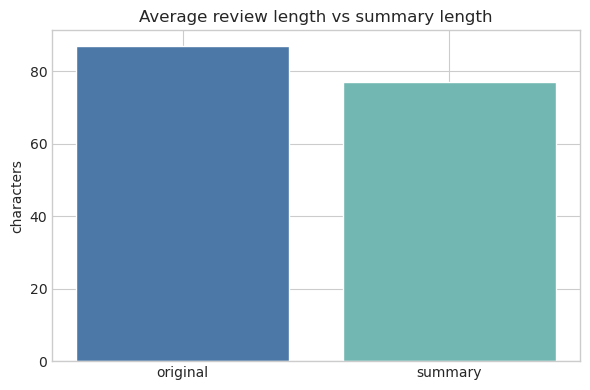

In [ ]:
# Compare average review length before and after summarization
df["summary_char_count"] = df["summary"].astype(str).str.len()
valid = df[df["review_char_count"] > 0]

avg_original = valid["review_char_count"].mean() if len(valid) else 0
avg_summary = valid["summary_char_count"].mean() if len(valid) else 0
compression_pct = (1 - (avg_summary / avg_original)) * 100 if avg_original else 0

compression_table = pd.DataFrame(
    {
        "metric": ["avg_original_chars", "avg_summary_chars", "compression_percent"],
        "value": [round(avg_original, 1), round(avg_summary, 1), round(compression_pct, 1)],
    }
)
display(compression_table)

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(
    ["original", "summary"],
    [avg_original, avg_summary],
    color=[FABRIC_BLUE, FABRIC_TEAL],
    edgecolor="white",
)
ax.set_title("Average review length vs summary length")
ax.set_ylabel("characters")
plt.tight_layout()
plt.show()

### 3.5 `ai.translate`

Translate summaries so the same workflow can support multilingual review processes.

In [ ]:
df["summary_spanish"] = df["summary"].ai.translate("spanish")

display(df[["summary", "summary_spanish"]].head(10))

StatementMeta(, e18f93f0-e0fd-40e4-a544-51ce147078bd, 75, Finished, Available, Finished, False)

/home/trusted-service-user/cluster-env/trident_env/lib/python3.13/site-packages/synapse/ml/aifunc/_client.py:272: UserWarning: conf.temperature is not supported for model gpt-5-mini; overriding to NOT_GIVEN
  warnings.warn(f"conf.temperature is not supported for model {model}; overriding to NOT_GIVEN")
ai.translate:   0%|          | 0/5 [00:00<?, ?it/s]

ai.translate:  20%|██        | 1/5 [00:01<00:06,  1.50s/it, cached=0->0.00, in=198->990.00, out=140->700.00, CU-s=9.58->47.89]

ai.translate:  80%|████████  | 4/5 [00:02<00:00,  2.73it/s, cached=0->0.00, in=782->977.50, out=580->725.00, CU-s=39.65->49.56]

ai.translate: 100%|██████████| 5/5 [00:04<00:00,  1.19it/s, cached=0, in=980, out=703, CU-s=48.09]


SynapseWidget(Synapse.DataFrame, 929307b7-ed22-4675-9760-bd872d2a17b6)

### 3.6 `ai.fix_grammar`

Clean up raw review text when you need something easier to share with business users.

In [ ]:
df["review_corrected"] = df["review_text"].ai.fix_grammar()

display(df[["review_text", "review_corrected"]].head(10))

StatementMeta(, e18f93f0-e0fd-40e4-a544-51ce147078bd, 76, Finished, Available, Finished, False)

/home/trusted-service-user/cluster-env/trident_env/lib/python3.13/site-packages/synapse/ml/aifunc/_client.py:272: UserWarning: conf.temperature is not supported for model gpt-5-mini; overriding to NOT_GIVEN
  warnings.warn(f"conf.temperature is not supported for model {model}; overriding to NOT_GIVEN")
ai.fix_grammar:   0%|          | 0/5 [00:00<?, ?it/s]

ai.fix_grammar:  20%|██        | 1/5 [00:01<00:05,  1.38s/it, cached=0->0.00, in=338->845.00, out=245->612.50, CU-s=16.76->41.89]

ai.fix_grammar:  80%|████████  | 4/5 [00:01<00:00,  2.80it/s, cached=0->0.00, in=672->840.00, out=592->740.00, CU-s=40.36->50.46]

ai.fix_grammar: 100%|██████████| 5/5 [00:03<00:00,  1.49it/s, cached=0, in=840, out=982, CU-s=66.73]


SynapseWidget(Synapse.DataFrame, 7e473b3e-9242-4839-a612-5bbfbeee8df5)

### 3.7 `ai.embed`

Generate embeddings for semantic search, clustering, and other vector-based workflows.

In [ ]:
df["embedding"] = df["review_text"].ai.embed()

# Quick sanity check: row count, vector dimension, and a preview of the first vector
embedding_overview = pd.DataFrame(
    {
        "metric": ["rows_with_embeddings", "embedding_dimension", "first_vector_preview"],
        "value": [
            int(df["embedding"].notna().sum()),
            len(df["embedding"].iloc[0]) if len(df) else 0,
            str(df["embedding"].iloc[0][:5]) if len(df) else "[]",
        ],
    }
)
display(embedding_overview)

StatementMeta(, e18f93f0-e0fd-40e4-a544-51ce147078bd, 77, Finished, Available, Finished, False)

/home/trusted-service-user/cluster-env/trident_env/lib/python3.13/site-packages/synapse/ml/aifunc/_client.py:272: UserWarning: conf.temperature is not supported for model gpt-5-mini; overriding to NOT_GIVEN
  warnings.warn(f"conf.temperature is not supported for model {model}; overriding to NOT_GIVEN")
ai.embed: 100%|██████████| 5/5 [00:00<00:00, 26.93it/s, cached=0, in=85, out=0, CU-s=0.29]


SynapseWidget(Synapse.DataFrame, 6e9a1a60-e051-4c67-968c-181b23c21210)

### 3.8 `ai.similarity`

Rank reviews against a focused business question to surface the most relevant rows first.

In [ ]:
# Score each review against a target query — higher means more semantically similar
query = "durability and product quality issues"
df["similarity_score"] = df["review_text"].ai.similarity(query)

display(
    df[["review_text", "similarity_score"]]
    .sort_values("similarity_score", ascending=False)
    .head(10)
)

StatementMeta(, e18f93f0-e0fd-40e4-a544-51ce147078bd, 78, Finished, Available, Finished, False)

/home/trusted-service-user/cluster-env/trident_env/lib/python3.13/site-packages/synapse/ml/aifunc/_client.py:272: UserWarning: conf.temperature is not supported for model gpt-5-mini; overriding to NOT_GIVEN
  warnings.warn(f"conf.temperature is not supported for model {model}; overriding to NOT_GIVEN")
ai.similarity:   0%|          | 0/5 [00:00<?, ?it/s]

ai.similarity: 100%|██████████| 5/5 [00:00<00:00, 31.77it/s, cached=0, in=91, out=0, CU-s=0.31]


SynapseWidget(Synapse.DataFrame, ed0d6b6a-46eb-45d6-a331-c7ee733b1c96)

### 3.9 `ai.generate_response`

Turn the upstream signals into a structured support recommendation that is easy to operationalize.

In [ ]:
# Pydantic schema for the structured support-response output
class ResponseSuggestion(BaseModel):
    reason: str = Field(description="Why this response strategy fits the review")
    response_type: Literal["thank_you", "apology", "follow_up", "no_response_needed"] = Field(
        description="Recommended response type"
    )
    priority: Literal["high", "medium", "low"] = Field(description="Support priority level")
    suggested_response: str = Field(description="Personalized 2-3 sentence response")

StatementMeta(, e18f93f0-e0fd-40e4-a544-51ce147078bd, 79, Finished, Available, Finished, False)

In [ ]:
# Prompt template — {review_text}, {sentiment}, and {topic} are filled per-row from the DataFrame
RESPONSE_PROMPT = dedent(
    """
    You are a helpful customer support assistant.

    Review:
    <review>{review_text}</review>

    Detected sentiment: {sentiment}
    Detected topic: {topic}

    Return a warm and practical response to the customer.
    - Factor in the context of the review.
    - If sentiment is negative, apologize and include a concrete next step.
    - If sentiment is positive, thank the customer and reinforce value.
    - Keep the suggested response to 2-3 sentences.
    """
).strip()

# Generate a structured response for every row using the upstream sentiment and topic signals
df["response_json"] = df.ai.generate_response(
    prompt=RESPONSE_PROMPT,
    is_prompt_template=True,
    response_format=ResponseSuggestion,
)

display(df[["review_text", "response_json"]].head(10))

StatementMeta(, e18f93f0-e0fd-40e4-a544-51ce147078bd, 80, Finished, Available, Finished, False)

/home/trusted-service-user/cluster-env/trident_env/lib/python3.13/site-packages/synapse/ml/aifunc/_client.py:272: UserWarning: conf.temperature is not supported for model gpt-5-mini; overriding to NOT_GIVEN
  warnings.warn(f"conf.temperature is not supported for model {model}; overriding to NOT_GIVEN")
ai.generate_response:   0%|          | 0/5 [00:00<?, ?it/s]

ai.generate_response:  20%|██        | 1/5 [00:02<00:07,  1.94s/it, cached=0->0.00, in=491->1.23k, out=415->1.04k, CU-s=28.31->70.78]

ai.generate_response: 100%|██████████| 5/5 [00:02<00:00,  2.16it/s, cached=0, in=1.23k, out=1.14k, CU-s=77.34]


SynapseWidget(Synapse.DataFrame, 73100d2c-34cb-4118-8e72-3fcc7045d239)

In [ ]:
# Parse the JSON string into individual columns for analysis and display
parsed_response = df["response_json"].astype(str).apply(json.loads)
df["response_reason"] = parsed_response.apply(lambda x: x.get("reason"))
df["response_type"] = parsed_response.apply(lambda x: x.get("response_type"))
df["priority"] = parsed_response.apply(lambda x: x.get("priority"))
df["suggested_response"] = parsed_response.apply(lambda x: x.get("suggested_response"))

response_columns = ["response_reason", "response_type", "priority", "suggested_response"]
display(df[response_columns].head(10))

display(df["response_type"].value_counts().rename_axis("response_type").reset_index(name="count"))
display(df["priority"].value_counts().rename_axis("priority").reset_index(name="count"))

StatementMeta(, e18f93f0-e0fd-40e4-a544-51ce147078bd, 81, Finished, Available, Finished, False)

SynapseWidget(Synapse.DataFrame, 91145774-e9a3-4e59-b64e-838df1322ecf)

SynapseWidget(Synapse.DataFrame, 0a57d0d6-9684-4468-b620-7d22d12e0bf4)

SynapseWidget(Synapse.DataFrame, c4215ba8-3e6a-45ee-b1ce-bf8904370ad0)

### 3.10 `ai.stats`

`ai.stats` is not an AI Function itself. It is a helper that summarizes the AI Function calls already run on the DataFrame, so you can review usage details such as request counts, success or failure totals, and token usage.

In [ ]:
stats = df.ai.stats
stats["columns"] = stats.index
display(stats)

StatementMeta(, e18f93f0-e0fd-40e4-a544-51ce147078bd, 82, Finished, Available, Finished, False)

SynapseWidget(Synapse.DataFrame, f55bbe5d-c728-496c-a002-f1e306ffaa17)

## 4. Build a triage dashboard

In [ ]:
# Aggregate the full pipeline into a single summary table
pipeline_summary = pd.DataFrame(
    {
        "metric": [
            "rows_processed",
            "unique_sentiments",
            "unique_topics",
            "negative_reviews",
            "high_priority_items",
        ],
        "value": [
            len(df),
            df["sentiment"].nunique(),
            df["topic"].nunique(),
            int((df["sentiment"].astype(str) == "negative").sum()),
            int((df["priority"].astype(str) == "high").sum()),
        ],
    }
)

display(pipeline_summary)

# Surface high-priority rows for manual review
display(
    df[df["priority"].astype(str) == "high"][
        ["review_text", "sentiment", "topic", "response_type", "suggested_response"]
    ].head(10)
)

StatementMeta(, e18f93f0-e0fd-40e4-a544-51ce147078bd, 83, Finished, Available, Finished, False)

SynapseWidget(Synapse.DataFrame, ca7a0c11-3881-434c-8d39-815a1a5d2e42)

SynapseWidget(Synapse.DataFrame, 5fefd551-d0c5-47b1-a85a-7d8d731a7a4b)

StatementMeta(, e18f93f0-e0fd-40e4-a544-51ce147078bd, 84, Finished, Available, Finished, False)

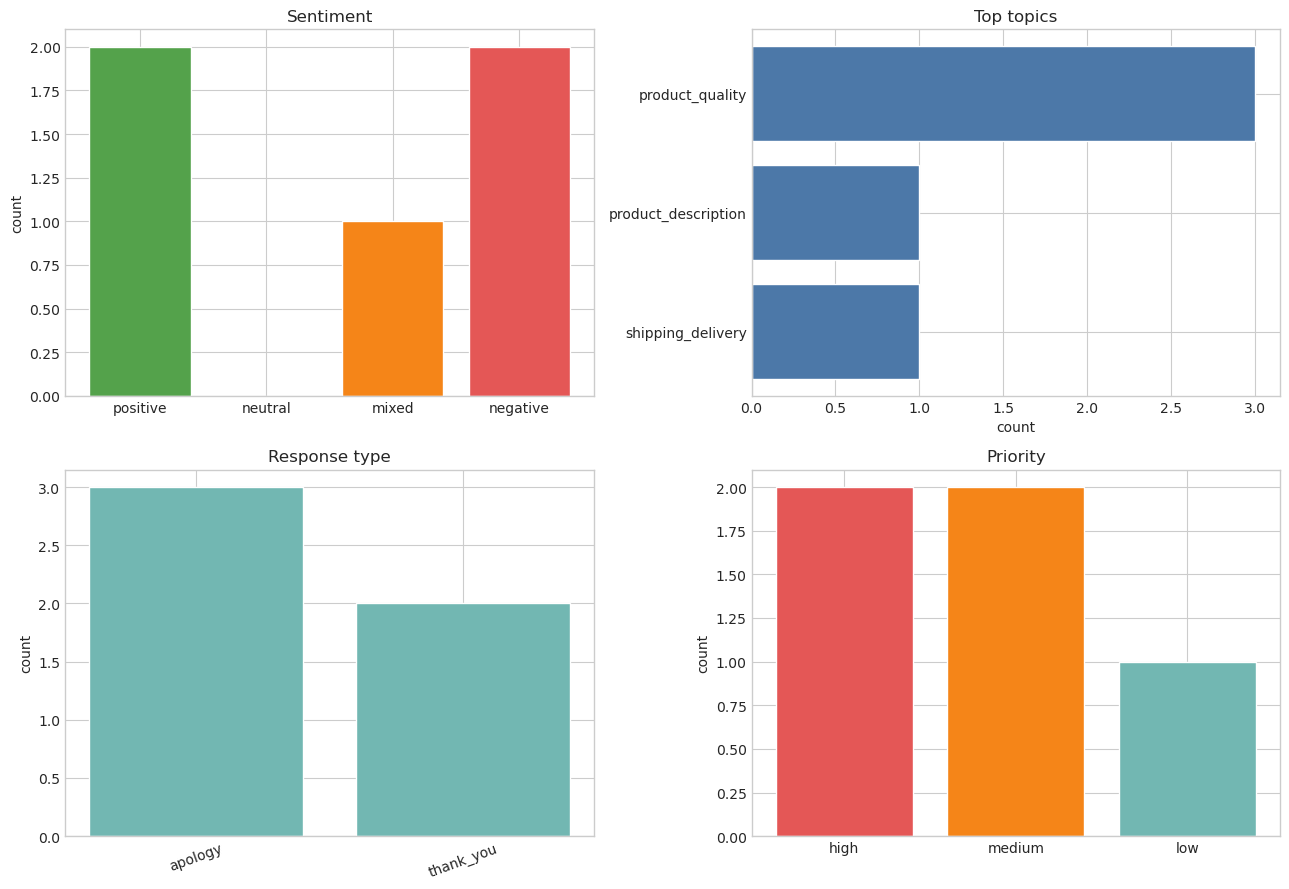

In [ ]:
# 2×2 triage dashboard: sentiment, topics, response types, and priority breakdown
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# Top-left: sentiment distribution
sentiment_dashboard = (
    df["sentiment"].astype(str).value_counts().reindex(["positive", "neutral", "mixed", "negative"])
    .fillna(0)
)
axes[0, 0].bar(
    sentiment_dashboard.index,
    sentiment_dashboard.values,
    color=[SENTIMENT_COLORS.get(value, FABRIC_BLUE) for value in sentiment_dashboard.index],
    edgecolor="white",
)
axes[0, 0].set_title("Sentiment")
axes[0, 0].set_ylabel("count")

# Top-right: most common topics
topic_dashboard = df["topic"].astype(str).value_counts().head(8).sort_values()
axes[0, 1].barh(topic_dashboard.index, topic_dashboard.values, color=FABRIC_BLUE, edgecolor="white")
axes[0, 1].set_title("Top topics")
axes[0, 1].set_xlabel("count")

# Bottom-left: response type breakdown
response_dashboard = df["response_type"].astype(str).value_counts()
axes[1, 0].bar(
    response_dashboard.index,
    response_dashboard.values,
    color=FABRIC_TEAL,
    edgecolor="white",
)
axes[1, 0].set_title("Response type")
axes[1, 0].set_ylabel("count")
axes[1, 0].tick_params(axis="x", rotation=20)

# Bottom-right: priority levels
priority_dashboard = (
    df["priority"].astype(str).value_counts().reindex(["high", "medium", "low"]).fillna(0)
)
axes[1, 1].bar(
    priority_dashboard.index,
    priority_dashboard.values,
    color=[PRIORITY_COLORS.get(value, FABRIC_BLUE) for value in priority_dashboard.index],
    edgecolor="white",
)
axes[1, 1].set_title("Priority")
axes[1, 1].set_ylabel("count")

plt.tight_layout()
plt.show()

## 5. Interpreting results and next steps

### How to use this workflow
- Use **sentiment + topic** to identify where customer pain points are clustering.
- Use **extract** to pull substrings from text fields such as products, brands, and issues into downstream triage.
- Use **summary + translation + grammar fixes** to make reviews easier to read and share.
- Use **similarity + structured response suggestions** to prioritize repeated issues and accelerate support follow-up.

### Next steps
- Increase `SAMPLE_ROWS` once the notebook quality and cost look right.
- Replace the sample dataset with your own data.
- Move to the PySpark AI Functions when the dataset grows beyond what you want to keep in memory locally (for example, more than 1 GB).
- Use eval notebooks when you want systematic quality measurement instead of a starter walkthrough.

### Learn more
- Starter notebooks: [aka.ms/fabric-aifunctions-starter-notebooks](https://aka.ms/fabric-aifunctions-starter-notebooks)
- Eval notebooks: [aka.ms/fabric-aifunctions-eval-notebooks](https://aka.ms/fabric-aifunctions-eval-notebooks)
- AI Functions overview: [aka.ms/ai-functions](https://aka.ms/ai-functions)
- [Pandas AI Function Config Doc](https://learn.microsoft.com/en-us/fabric/data-science/ai-functions/pandas/configuration)
- Model catalog: [aka.ms/fabric-ai-models](https://aka.ms/fabric-ai-models)
